# Part 1 — Learning a 2D Flow from Scratch

A small MLP learns a velocity field that carries a 2D Gaussian (t = 0) onto eight clusters on a ring (t = 1).

In [1]:
import json
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

ROOT = Path.cwd()
OUT = ROOT / "outputs" / "part1"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cpu")

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "device": str(device),
    "cpu": platform.processor(),
    "platform": platform.platform(),
    "torch_threads": torch.get_num_threads(),
    "seed": SEED,
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'numpy': '2.2.2',
 'matplotlib': '3.11.1',
 'device': 'cpu',
 'cpu': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'platform': 'Windows-11-10.0.26300-SP0',
 'torch_threads': 6,
 'seed': 0}

## Task 1 — Source, target, and training pairs

Source $x_0 \sim \mathcal{N}(0, I)$; target = one of 8 centres at radius 3 chosen uniformly, plus $\mathcal{N}(0, 0.25^2 I)$ noise.

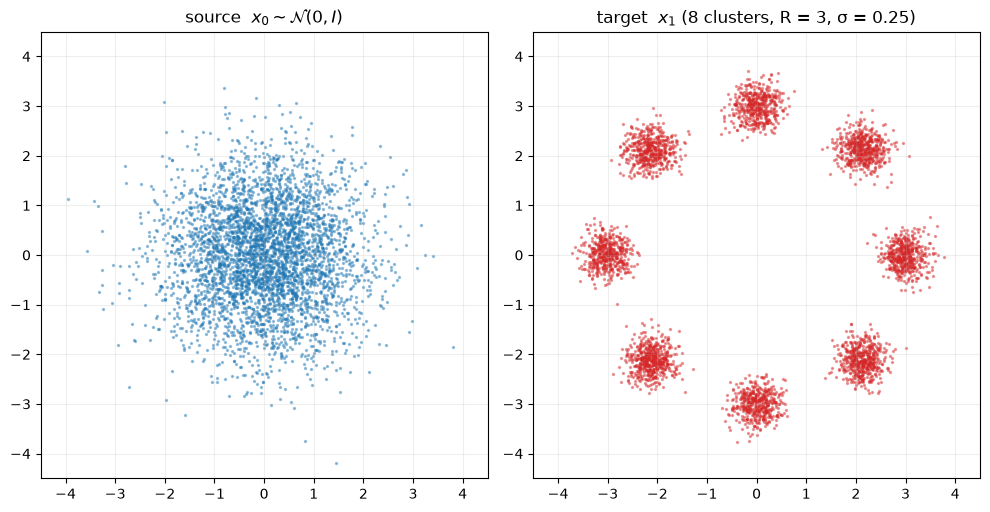

In [2]:
N_CLUSTERS, RADIUS, CLUSTER_STD = 8, 3.0, 0.25
angles = 2 * np.pi * np.arange(N_CLUSTERS) / N_CLUSTERS
CENTRES = torch.tensor(np.stack([RADIUS * np.cos(angles), RADIUS * np.sin(angles)], 1), dtype=torch.float32)


def sample_source(n, generator=None):
    return torch.randn(n, 2, generator=generator)


def sample_target(n, generator=None):
    """Eight-cluster ring: uniform cluster choice plus isotropic Gaussian noise."""
    k = torch.randint(0, N_CLUSTERS, (n,), generator=generator)
    return CENTRES[k] + CLUSTER_STD * torch.randn(n, 2, generator=generator)


g = torch.Generator().manual_seed(1)
x0_demo, x1_demo = sample_source(4000, g), sample_target(4000, g)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, pts, title, col in [(axes[0], x0_demo, "source  $x_0 \\sim \\mathcal{N}(0, I)$", "tab:blue"),
                            (axes[1], x1_demo, "target  $x_1$ (8 clusters, R = 3, σ = 0.25)", "tab:red")]:
    ax.scatter(*pts.T, s=2, alpha=0.4, color=col)
    ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect="equal", title=title)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "task1_source_target.png", dpi=130, bbox_inches="tight")
plt.show()

### Random pairs, interpolated points, and target velocities

Source and target points are paired at random, with $x_t = (1-t)x_0 + t x_1$ and $u = x_1 - x_0$ for $t \sim U(0, 1)$.

In [3]:
def make_training_batch(n, generator=None):
    """Independent (random) coupling of source and target, a uniform time, the interpolant, and its velocity."""
    x0 = sample_source(n, generator)
    x1 = sample_target(n, generator)
    t = torch.rand(n, 1, generator=generator)
    xt = (1 - t) * x0 + t * x1
    u = x1 - x0
    return x0, x1, t, xt, u


g = torch.Generator().manual_seed(2)
x0, x1, t, xt, u = make_training_batch(5, g)
for i in range(5):
    print(f"x0={x0[i].numpy().round(2)}  x1={x1[i].numpy().round(2)}  t={t[i].item():.2f}  "
          f"x_t={xt[i].numpy().round(2)}  u={u[i].numpy().round(2)}")

x0=[ 0.39 -0.22]  x1=[-2.6   0.14]  t=0.75  x_t=[-1.84  0.05]  u=[-2.99  0.36]
x0=[-0.32 -1.21]  x1=[-2.76  0.09]  t=0.71  x_t=[-2.06 -0.28]  u=[-2.44  1.29]
x0=[ 1.04 -0.63]  x1=[-2.22 -2.23]  t=0.52  x_t=[-0.66 -1.47]  u=[-3.27 -1.6 ]
x0=[0.57 0.54]  x1=[ 1.68 -2.02]  t=0.55  x_t=[ 1.18 -0.88]  u=[ 1.11 -2.56]
x0=[-0.39 -1.04]  x1=[-2.21  2.43]  t=0.54  x_t=[-1.37  0.83]  u=[-1.82  3.47]


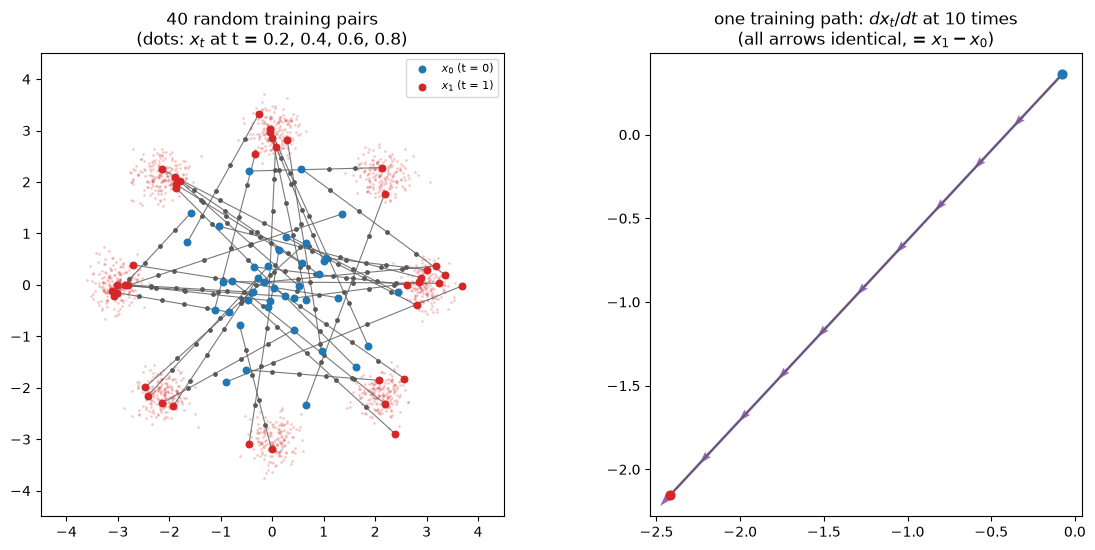

finite-difference velocities along path 0:
 [[-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]
 [-2.3429 -2.5151]]
x1 - x0 for path 0: [-2.3429 -2.5151]


In [4]:
g = torch.Generator().manual_seed(3)
n_paths = 40
x0, x1, _, _, _ = make_training_batch(n_paths, g)
ts = torch.linspace(0, 1, 6).reshape(-1, 1, 1)
pts = (1 - ts) * x0 + ts * x1                     # (6, n_paths, 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
ax = axes[0]
ax.scatter(*x1_demo[:1500].T, s=1.5, color="tab:red", alpha=0.15)
for i in range(n_paths):
    ax.plot(pts[:, i, 0], pts[:, i, 1], color="0.35", lw=0.8, alpha=0.8)
    ax.scatter(pts[1:-1, i, 0], pts[1:-1, i, 1], s=6, color="0.35")
ax.scatter(*x0.T, s=22, color="tab:blue", zorder=3, label="$x_0$ (t = 0)")
ax.scatter(*x1.T, s=22, color="tab:red", zorder=3, label="$x_1$ (t = 1)")
ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect="equal",
       title=f"{n_paths} random training pairs\n(dots: $x_t$ at t = 0.2, 0.4, 0.6, 0.8)")
ax.legend(loc="upper right", fontsize=8)

# the velocity along one path, sampled at many times, is the same vector every time
ax = axes[1]
i = 0
tt = torch.linspace(0, 1, 11).reshape(-1, 1)
path = (1 - tt) * x0[i] + tt * x1[i]
finite_diff = (path[1:] - path[:-1]) / (tt[1:] - tt[:-1])
ax.plot(*path.T, color="0.35", lw=1)
ax.quiver(path[:-1, 0], path[:-1, 1], finite_diff[:, 0], finite_diff[:, 1], angles="xy",
          scale_units="xy", scale=8, width=0.006, color="tab:purple")
ax.scatter(*x0[i], s=40, color="tab:blue", zorder=3)
ax.scatter(*x1[i], s=40, color="tab:red", zorder=3)
ax.set(aspect="equal", title="one training path: $dx_t/dt$ at 10 times\n(all arrows identical, = $x_1 - x_0$)")
plt.tight_layout()
plt.savefig(OUT / "task1_training_paths.png", dpi=130, bbox_inches="tight")
plt.show()
print("finite-difference velocities along path 0:\n", finite_diff.numpy().round(4))
print("x1 - x0 for path 0:", (x1[i] - x0[i]).numpy().round(4))

### Why the velocity is constant along each path

$x_t$ is linear in $t$, so $dx_t/dt = x_1 - x_0$ at every point on the path, as the identical finite differences confirm.

## Task 2 — Velocity model and training loop

The MLP (3 hidden layers of width 128, SiLU) maps $(x, y, t)$ to a 2D velocity and is trained with $\mathcal{L} = \mathbb{E}\|v_\theta(x_t, t) - (x_1 - x_0)\|^2$.

In [5]:
class VelocityMLP(nn.Module):
    """v_theta(x, t): R^2 x [0, 1] -> R^2."""

    def __init__(self, hidden=128, depth=3):
        super().__init__()
        layers, d = [], 3
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        if not torch.is_tensor(t) or t.dim() == 0:
            t = torch.full((x.shape[0], 1), float(t))
        return self.net(torch.cat([x, t.reshape(-1, 1)], dim=1))


def flow_matching_loss(model, xt, t, u):
    return ((model(xt, t) - u) ** 2).sum(dim=1).mean()


def train_flow(model, batch_fn, steps, batch_size=256, lr=1e-3, seed=0):
    """Adam with cosine learning-rate decay; batch_fn(n, generator) -> (xt, t, u)."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.05)
    losses = np.empty(steps)
    t_start = time.perf_counter()
    for step in range(steps):
        xt, t, u = batch_fn(batch_size, g)
        loss = flow_matching_loss(model, xt, t, u)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses[step] = loss.item()
    return losses, time.perf_counter() - t_start


CONFIG = {"hidden": 128, "depth": 3, "activation": "SiLU", "batch_size": 256, "steps": 20000,
          "lr": 1e-3, "lr_schedule": "cosine to 5% of lr", "optimizer": "Adam", "seed": SEED,
          "coupling": "independent (random pairs)", "target": "8 clusters, R=3, std=0.25"}

torch.manual_seed(SEED)
model = VelocityMLP(CONFIG["hidden"], CONFIG["depth"])
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("parameters:", n_params)

VelocityMLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
parameters: 33794


In [6]:
def random_pair_batch(n, g):
    _, _, t, xt, u = make_training_batch(n, g)
    return xt, t, u


losses, train_seconds = train_flow(model, random_pair_batch, CONFIG["steps"], CONFIG["batch_size"],
                                   CONFIG["lr"], seed=SEED)
print(f"trained {CONFIG['steps']} steps in {train_seconds:.1f} s "
      f"({1000 * train_seconds / CONFIG['steps']:.2f} ms/step, {torch.get_num_threads()} threads)")
print(f"mean loss, first 500 steps: {losses[:500].mean():.3f} | last 2000 steps: {losses[-2000:].mean():.3f}")

torch.save({"state_dict": model.state_dict(), "config": CONFIG}, OUT / "baseline_model.pt")
np.save(OUT / "train_losses.npy", losses)
(OUT / "train_config.json").write_text(json.dumps({**CONFIG, "parameters": n_params,
                                                    "train_seconds": train_seconds}, indent=2))

trained 20000 steps in 63.1 s (3.15 ms/step, 6 threads)
mean loss, first 500 steps: 6.651 | last 2000 steps: 5.696


333

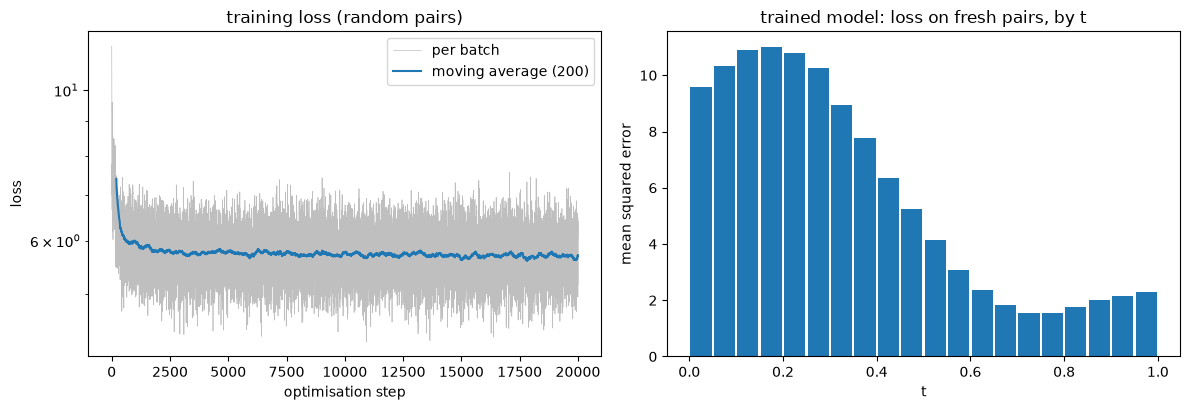

loss by t-bin: [ 9.58 10.33 10.91 11.01 10.8  10.25  8.94  7.76  6.33  5.26  4.14  3.09
  2.37  1.83  1.56  1.56  1.76  2.    2.14  2.29]


In [7]:
def moving_average(x, w=200):
    return np.convolve(x, np.ones(w) / w, mode="valid")


# loss as a function of t on fresh pairs, after training
g = torch.Generator().manual_seed(4)
xt, t, u = random_pair_batch(200_000, g)
with torch.no_grad():
    per_example = ((model(xt, t) - u) ** 2).sum(1).numpy()
bins = np.linspace(0, 1, 21)
idx = np.digitize(t.numpy().ravel(), bins) - 1
loss_by_t = np.array([per_example[idx == b].mean() for b in range(20)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(losses, color="0.75", lw=0.5, label="per batch")
axes[0].plot(np.arange(199, len(losses)), moving_average(losses), color="tab:blue", label="moving average (200)")
axes[0].set(xlabel="optimisation step", ylabel="loss", yscale="log", title="training loss (random pairs)")
axes[0].legend()
axes[1].bar((bins[:-1] + bins[1:]) / 2, loss_by_t, width=0.045, color="tab:blue")
axes[1].set(xlabel="t", ylabel="mean squared error", title="trained model: loss on fresh pairs, by t")
plt.tight_layout()
plt.savefig(OUT / "task2_training_loss.png", dpi=130, bbox_inches="tight")
plt.show()
print("loss by t-bin:", loss_by_t.round(2))

### What is being predicted

The model can only learn the average velocity $\mathbb{E}[x_1 - x_0 \mid x_t, t]$, so the loss levels off at the variance of crossing random pairs instead of reaching zero.

## Task 3 — Generating new points with forward Euler

$z_{k+1} = z_k + \Delta t\, v_\theta(z_k, t_k)$, starting from fresh Gaussian samples with no endpoints given.

In [8]:
@torch.no_grad()
def euler_sample(model, z0, n_steps, return_path=False):
    """Forward Euler from t=0 to t=1. Returns final points, plus the (n_steps+1, N, 2) path if asked."""
    z = z0.clone()
    dt = 1.0 / n_steps
    path = [z.clone()] if return_path else None
    for k in range(n_steps):
        z = z + dt * model(z, k * dt)
        if return_path:
            path.append(z.clone())
    return (z, torch.stack(path)) if return_path else z


model.eval()
K = 100
z0 = sample_source(4000, torch.Generator().manual_seed(100))
t0 = time.perf_counter()
z1, path = euler_sample(model, z0, K, return_path=True)
print(f"{K} Euler steps for {len(z0)} points: {time.perf_counter() - t0:.3f} s, {K} network evaluations per point")
np.save(OUT / "generated_K100.npy", z1.numpy())

100 Euler steps for 4000 points: 0.450 s, 100 network evaluations per point


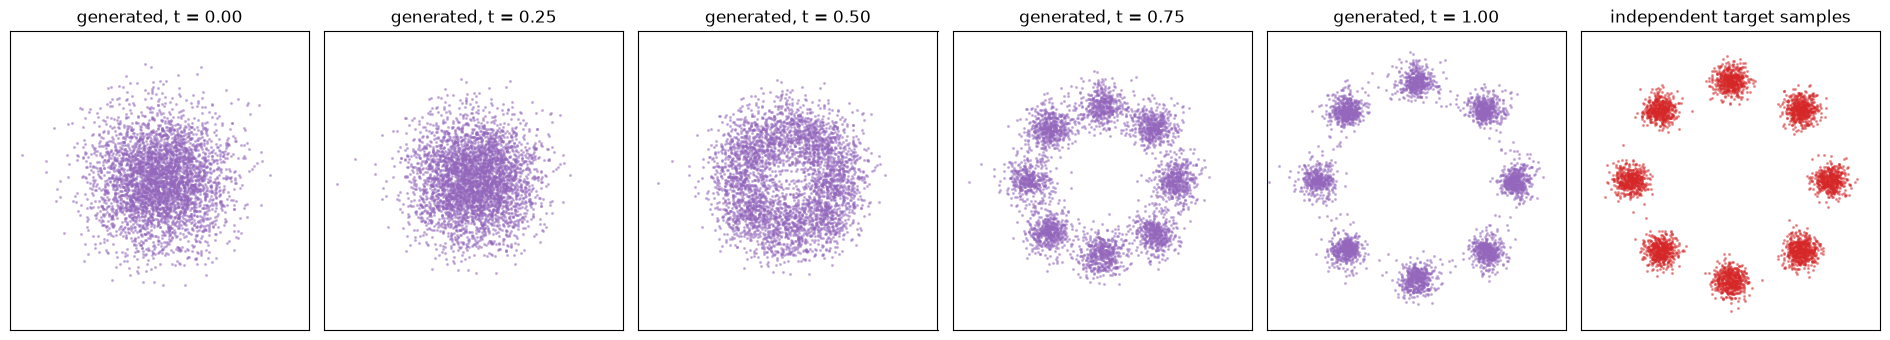

In [9]:
snap_ts = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axes = plt.subplots(1, len(snap_ts) + 1, figsize=(19, 3.6))
for ax, s in zip(axes, snap_ts):
    pts = path[int(round(s * K))]
    ax.scatter(*pts.T, s=1.5, alpha=0.4, color="tab:purple")
    ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect="equal", title=f"generated, t = {s:.2f}")
axes[-1].scatter(*sample_target(4000, torch.Generator().manual_seed(101)).T, s=1.5, alpha=0.4, color="tab:red")
axes[-1].set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect="equal", title="independent target samples")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUT / "task3_generation_snapshots.png", dpi=130, bbox_inches="tight")
plt.show()

### Learned velocity field at selected times

Arrows show $v_\theta(x, t)$ on a fixed grid, coloured by speed, with that time's particles in grey.

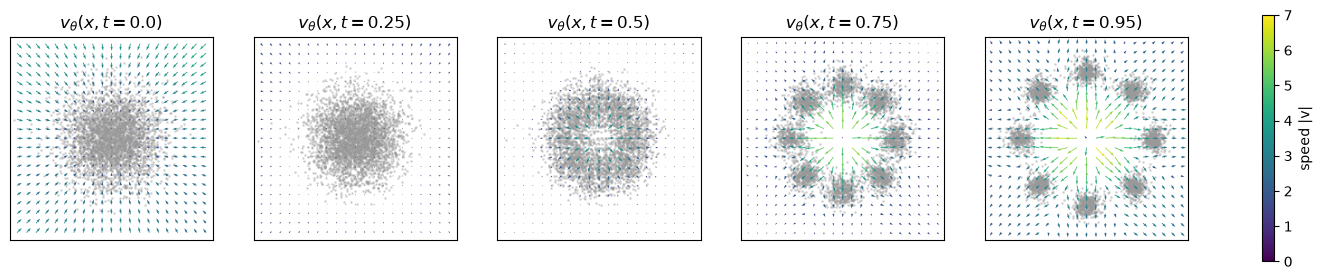

In [10]:
grid = torch.linspace(-4, 4, 21)
gx, gy = torch.meshgrid(grid, grid, indexing="xy")
gpts = torch.stack([gx.ravel(), gy.ravel()], 1)
field_ts = [0.0, 0.25, 0.5, 0.75, 0.95]

fig, axes = plt.subplots(1, len(field_ts), figsize=(19, 4))
with torch.no_grad():
    for ax, s in zip(axes, field_ts):
        v = model(gpts, s)
        speed = v.norm(dim=1)
        ax.scatter(*path[int(round(s * K))].T, s=1, color="0.6", alpha=0.3)
        q = ax.quiver(gpts[:, 0], gpts[:, 1], v[:, 0], v[:, 1], speed, cmap="viridis",
                      angles="xy", scale_units="xy", scale=12, width=0.004, clim=(0, 7))
        ax.set(xlim=(-4.3, 4.3), ylim=(-4.3, 4.3), aspect="equal", title=f"$v_\\theta(x, t={s})$")
        ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(q, ax=axes, shrink=0.8, label="speed |v|")
plt.savefig(OUT / "task3_velocity_fields.png", dpi=130, bbox_inches="tight")
plt.show()

The field points inward at $t = 0$ (toward the target mean), is near zero at $t \approx 0.25$, and then pushes outward into eight basins.

### Learned trajectories vs. straight training paths

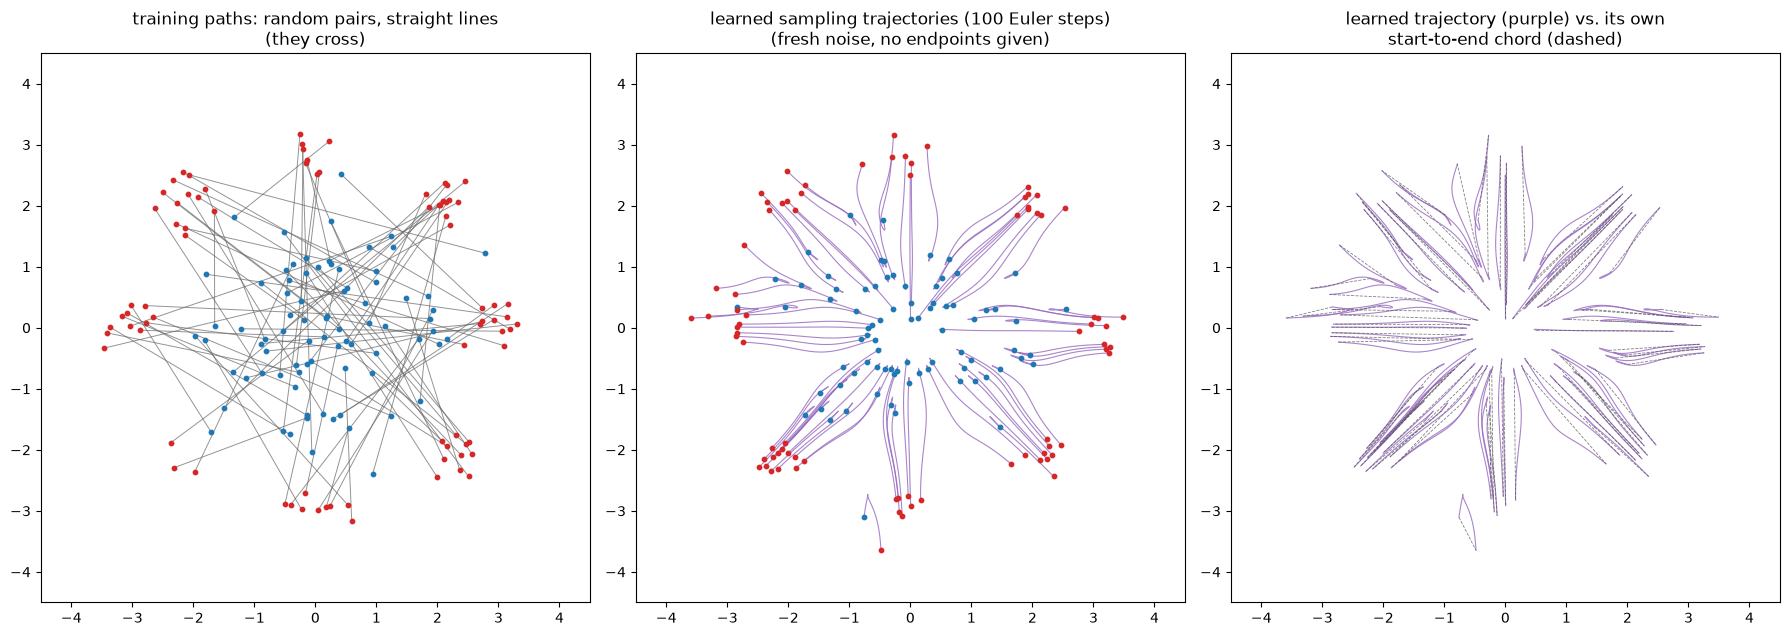

mean trajectory length 2.022 | mean start-to-end distance 1.767 | excess length 0.255 | length/chord ratio 1.186
fraction of trajectories with >5% excess length: 0.862


In [11]:
n_show = 80
g = torch.Generator().manual_seed(5)
x0_tr, x1_tr, _, _, _ = make_training_batch(n_show, g)
z0_s = sample_source(n_show, torch.Generator().manual_seed(6))
z1_s, path_s = euler_sample(model, z0_s, K, return_path=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
ax = axes[0]
for i in range(n_show):
    ax.plot([x0_tr[i, 0], x1_tr[i, 0]], [x0_tr[i, 1], x1_tr[i, 1]], color="0.4", lw=0.7, alpha=0.7)
ax.scatter(*x0_tr.T, s=10, color="tab:blue", zorder=3)
ax.scatter(*x1_tr.T, s=10, color="tab:red", zorder=3)
ax.set_title("training paths: random pairs, straight lines\n(they cross)")

ax = axes[1]
for i in range(n_show):
    ax.plot(path_s[:, i, 0], path_s[:, i, 1], color="tab:purple", lw=0.8, alpha=0.8)
ax.scatter(*z0_s.T, s=10, color="tab:blue", zorder=3)
ax.scatter(*z1_s.T, s=10, color="tab:red", zorder=3)
ax.set_title(f"learned sampling trajectories ({K} Euler steps)\n(fresh noise, no endpoints given)")

ax = axes[2]
for i in range(n_show):
    ax.plot(path_s[:, i, 0], path_s[:, i, 1], color="tab:purple", lw=0.8, alpha=0.8)
    ax.plot([z0_s[i, 0], z1_s[i, 0]], [z0_s[i, 1], z1_s[i, 1]], color="0.3", lw=0.6, ls="--", alpha=0.7)
ax.set_title("learned trajectory (purple) vs. its own\nstart-to-end chord (dashed)")
for ax in axes:
    ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect="equal")
plt.tight_layout()
plt.savefig(OUT / "task3_trajectories_vs_training_paths.png", dpi=130, bbox_inches="tight")
plt.show()

# path straightness on the full 4000-point sample (same 100-step grid)
seg = (path[1:] - path[:-1]).norm(dim=2).sum(0)
chord = (path[-1] - path[0]).norm(dim=1)
print(f"mean trajectory length {seg.mean():.3f} | mean start-to-end distance {chord.mean():.3f} | "
      f"excess length {(seg - chord).mean():.3f} | length/chord ratio {(seg / chord).mean():.3f}")
print(f"fraction of trajectories with >5% excess length: {((seg / chord) > 1.05).float().mean():.3f}")

Training paths are straight and cross, while the learned ODE trajectories never cross and come out noticeably curved.

In [12]:
summary = {
    "parameters": n_params,
    "train_steps": CONFIG["steps"],
    "train_seconds": round(train_seconds, 2),
    "final_loss_last2000_mean": float(losses[-2000:].mean()),
    "sampling_steps": K,
    "mean_excess_length": float((seg - chord).mean()),
    "mean_length_over_chord": float((seg / chord).mean()),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'parameters': 33794,
 'train_steps': 20000,
 'train_seconds': 63.1,
 'final_loss_last2000_mean': 5.69576873588562,
 'sampling_steps': 100,
 'mean_excess_length': 0.2554153800010681,
 'mean_length_over_chord': 1.1857106685638428}